# Projeto Integrador Avançado: VulcanTech Smart Metals S.A.
## Etapa 2: Inteligência Preditiva Multiclasse, MLOps, Explicabilidade SHAP e Impacto no OEE

Este notebook executa o ciclo completo de modelagem de Machine Learning para o chão de fábrica da VulcanTech:
- Particionamento temporal estrito (70% treino / 30% teste) sem contaminação cronológica;
- Tratamento de desbalanceamento de falhas via SMOTE no conjunto de treinamento;
- Treinamento comparativo de ensembles (`RandomForest` vs `LightGBM`) com otimização hiperparamétrica;
- Validação diagnóstica visando **Recall $\ge 90\%$** em todos os modos de falha crítica;
- Simulação do impacto preditivo no **OEE (Overall Equipment Effectiveness)** e malha fechada;
- Detecção não supervisionada de anomalias com `IsolationForest`;
- Interpretabilidade física através de **Feature Importances** e **SHAP Values**;
- Serialização MLOps dos artefatos em `models/`.

In [1]:
import os
from pathlib import Path
import sys

# Ajusta o diretório de trabalho para a raiz do repositório
caminho_raiz = Path.cwd().parent
if str(caminho_raiz) not in sys.path:
    sys.path.append(str(caminho_raiz))
os.chdir(caminho_raiz)

# Importações de módulos do sistema e bibliotecas científicas
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src.ml.train import IndustrialModelTrainer
from src.ml.evaluation import IndustrialModelEvaluator
from src.ml.oee_calculator import IndustrialOEECalculator

# Estilização gráfica industrial
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.size'] = 10
print(f'Ambiente inicializado na raiz: {os.getcwd()}')


C:\Phyton\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Ambiente inicializado na raiz: C:\Users\andre_matteussi\Documents\GitHub\vulcantech-edge-ai


## 1. Divisão Temporal Estrita (70% Treino / 30% Teste) e Rebalanceamento com SMOTE
Os dados são particionados estritamente pela linha do tempo (sem embaralhamento) para espelhar a operação real em chão de fábrica. O `RobustScaler` é ajustado exclusivamente sobre a partição de treino. Em seguida, o `SMOTE` reequilibra as amostras raras de falha.

In [2]:
trainer = IndustrialModelTrainer('data/processed/features_eng.parquet')
X_train, X_test, y_train, y_test = trainer.preparar_dados(
    target_col='tipo_falha',
    proporcao_treino=0.7
)

print(f'Dimensões do Treino: {X_train.shape} | Teste: {X_test.shape}')
print(f'\nDistribuição Original no Treino:\n{y_train.value_counts().sort_index()}')

# Aplicação do SMOTE estritamente na partição de treinamento
X_train_smote, y_train_smote = trainer.balancear_treino_smote()
print(f'\nDistribuição após SMOTE no Treino:\n{pd.Series(y_train_smote).value_counts().sort_index()}')


Dimensões do Treino: (7000, 33) | Teste: (3000, 33)

Distribuição Original no Treino:
tipo_falha
0    5994
1     338
2     341
3     327
Name: count, dtype: int64

Distribuição após SMOTE no Treino:
tipo_falha
0    5994
1    5994
2    5994
3    5994
Name: count, dtype: int64


## 2. Modelagem Multiclasse Supervisionada (Random Forest vs. LightGBM)
Treinamento dos estimadores ensemble com otimização hiperparamétrica via `RandomizedSearchCV` focado na métrica `recall_macro` para garantir atendimento aos requisitos de confiabilidade industrial.


================ Desempenho do Modelo: RandomForest ================
                       precision    recall  f1-score   support

               Normal     0.9996    0.9992    0.9994      2563
  Desgaste_Ferramenta     0.9847    0.9773    0.9810       132
   Falha_Refrigeracao     0.9882    0.9940    0.9911       168
Desalinhamento_Trinca     0.9783    0.9854    0.9818       137

             accuracy                         0.9973      3000
            macro avg     0.9877    0.9890    0.9883      3000
         weighted avg     0.9973    0.9973    0.9973      3000



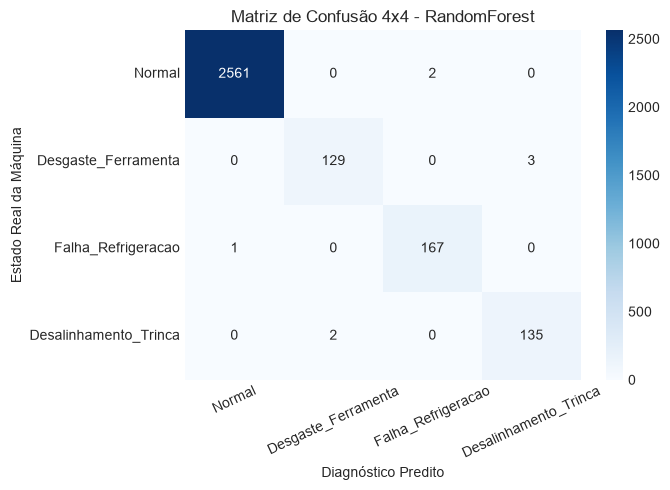


================ Desempenho do Modelo: LightGBM ================
                       precision    recall  f1-score   support

               Normal     0.9992    0.9980    0.9986      2563
  Desgaste_Ferramenta     0.9695    0.9621    0.9658       132
   Falha_Refrigeracao     0.9767    1.0000    0.9882       168
Desalinhamento_Trinca     0.9781    0.9781    0.9781       137

             accuracy                         0.9957      3000
            macro avg     0.9809    0.9846    0.9827      3000
         weighted avg     0.9957    0.9957    0.9957      3000



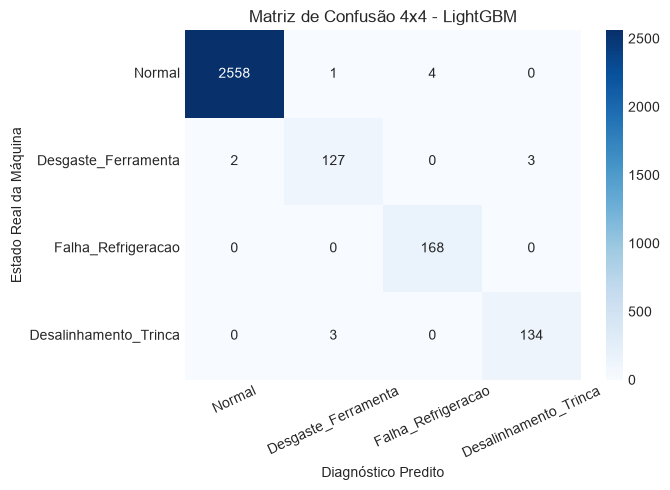

,Modelo,Acurácia,Recall Macro,F1-Score Macro,Recall Desgaste,Recall Refrigeração,Recall Trinca
0,RandomForest,0.9973,0.9890,0.9883,0.9773,0.994,0.9854
1,LightGBM,0.9957,0.9846,0.9827,0.9621,1.000,0.9781


In [3]:
modelos_treinados = trainer.treinar_supervisionados(X_train_smote, y_train_smote)

relatorios = {}
for nome, modelo in modelos_treinados.items():
    relatorios[nome] = IndustrialModelEvaluator.avaliar_classificador(
        modelo=modelo,
        X_test=X_test,
        y_test=y_test,
        nome_modelo=nome,
        exibir_grafico=True
    )

# Tabela comparativa oficial
tabela_comparativa = IndustrialModelEvaluator.comparar_desempenho(relatorios)
display(tabela_comparativa)


## 3. Módulo de Cálculo Preditivo e Simulação de Impacto no OEE
Modelagem do impacto preditivo no OEE industrial ($OEE = Disponibilidade \times Performance \times Qualidade$):
- **Disponibilidade**: penalizada por risco iminente de colisão, quebra de fuso ou troca de matriz (Classes 1 e 3);
- **Qualidade**: penalizada por distorções térmicas e perda de tolerância micrométrica (Classe 2);
- **Ações de Malha Fechada**: `MANTER_OPERACAO`, `REDUZIR_VELOCIDADE_50%` ou `INTERROMPER_EMERGENCIA`.

In [4]:
oee_calc = IndustrialOEECalculator()

# Identificação do melhor modelo
melhor_nome = tabela_comparativa.sort_values(by='Recall Macro', ascending=False).iloc[0]['Modelo']
melhor_classificador = modelos_treinados[melhor_nome]
y_pred_teste = melhor_classificador.predict(X_test)

# Simulação no conjunto de teste (3000 amostras)
resumo_oee = oee_calc.simular_impacto_lote(pd.Series(y_pred_teste))

print('=== Diagnóstico Preditivo de OEE no Conjunto de Teste ===')
print(f'Total de ciclos simulados: {resumo_oee["total_amostras"]}')
print(f'OEE Nominal de Referência (Sem Falhas): {resumo_oee["oee_nominal_referencia"] * 100:.2f}%')
print(f'OEE Médio Estimado em Regime de Falha: {resumo_oee["oee_medio_operacional"] * 100:.2f}%')
print(f'Perda Operacional Evitável por Manutenção Preditiva: {resumo_oee["gap_oee_medio"]:.2f} p.p.')

print('\nAções de Malha Fechada Recomendadas para os Controladores (CLP):')
for acao, qtd in resumo_oee['distribuicao_acoes_clp'].items():
    print(f'  • {acao}: {qtd} eventos ({qtd / len(y_pred_teste) * 100:.2f}%)')


=== Diagnóstico Preditivo de OEE no Conjunto de Teste ===
Total de ciclos simulados: 3000
OEE Nominal de Referência (Sem Falhas): 88.44%
OEE Médio Estimado em Regime de Falha: 82.41%
Perda Operacional Evitável por Manutenção Preditiva: 6.04 p.p.

Ações de Malha Fechada Recomendadas para os Controladores (CLP):
  • MANTER_OPERACAO: 2562 eventos (85.40%)
  • REDUZIR_VELOCIDADE_50%: 300 eventos (10.00%)
  • INTERROMPER_EMERGENCIA: 138 eventos (4.60%)


## 4. Detecção Não Supervisionada de Anomalias (Isolation Forest)
Treinamento do `IsolationForest` com dados de regime exclusivamente nominal (`tipo_falha == 0`) para sinalizar anomalias emergentes não mapeadas na telemetria.

In [5]:
modelo_iso = trainer.treinar_isolation_forest()

pred_iso = modelo_iso.predict(X_test)
total_anomalias = (pred_iso == -1).sum()
print(f'Total de instâncias classificadas como anomalias não supervisionadas no teste: {total_anomalias} ({total_anomalias / len(X_test) * 100:.2f}%)')


Total de instâncias classificadas como anomalias não supervisionadas no teste: 450 (15.00%)


## 5. Explicabilidade Física (Feature Importances & SHAP) e Serialização MLOps
Análise das variáveis com maior relevância na árvore de decisão e salvamento definitivo dos artefatos treinados em `models/`.

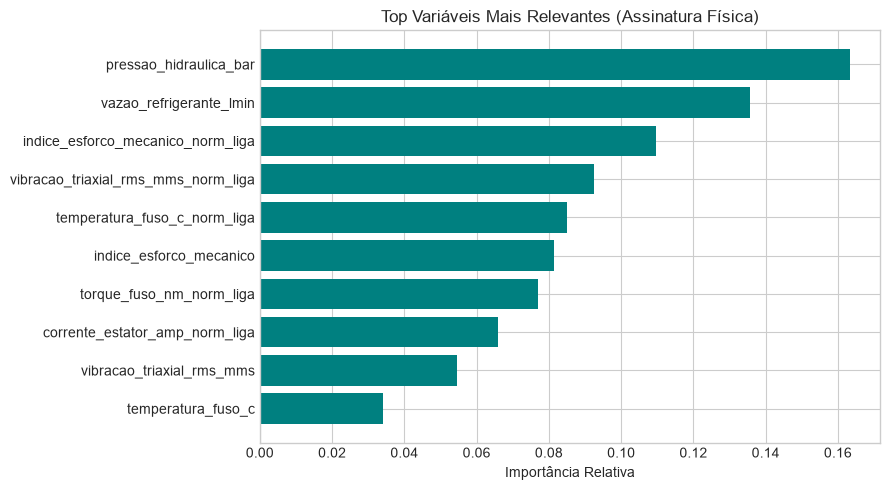

<Figure size 1000x600 with 0 Axes>

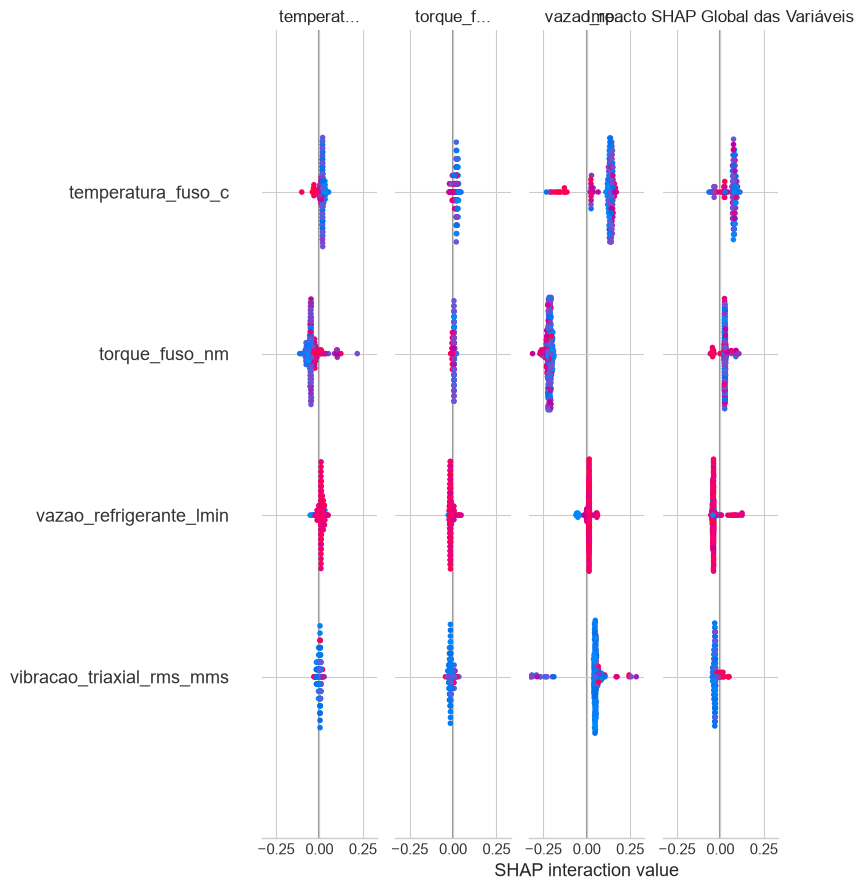

Artefatos salvos com sucesso no diretório 'models/'.


In [6]:
# 1. Feature Importances
IndustrialModelEvaluator.plotar_feature_importance(
    modelo=melhor_classificador,
    feature_names=trainer.feature_names,
    top_n=10,
    exibir_grafico=True
)

# 2. Explicabilidade SHAP
X_sample = X_test.iloc[:200]
IndustrialModelEvaluator.gerar_explicabilidade_shap(
    modelo=melhor_classificador,
    X_sample=X_sample,
    feature_names=trainer.feature_names,
    max_display=10,
    exibir_grafico=True
)

# 3. Exportação definitiva dos artefatos em models/
trainer.salvar_artefatos(
    melhor_classificador=melhor_classificador,
    modelo_iso=modelo_iso,
    pasta_destino='models'
)
